# EP1 — Classificação de avaliações de clareza e-SIC

Análise dos **resultados históricos salvos**, sem retreinar modelos. As médias vêm da validação usada para escolher hiperparâmetros e podem ser otimistas. Não são acurácias medidas em teste independente. Os grids atuais podem diferir daqueles que originaram os resumos históricos.

Classes: `c1` (nota 1), `c234` (notas 2–4), `c5` (nota 5).

In [ ]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from data_utils import normalized_groups

ROOT = Path.cwd()
if not (ROOT / "baseline_classifier.py").exists():
    raise RuntimeError("Execute o notebook a partir da pasta EP1.")


## Dados e distribuição das classes

,Medida,Valor
0,Linhas originais,20092
1,Linhas válidas,20092
2,Grupos textuais,18143
3,Grupos com rótulos conflitantes,316


,Exemplos
clarity,
c1,6347
c234,6853
c5,6892


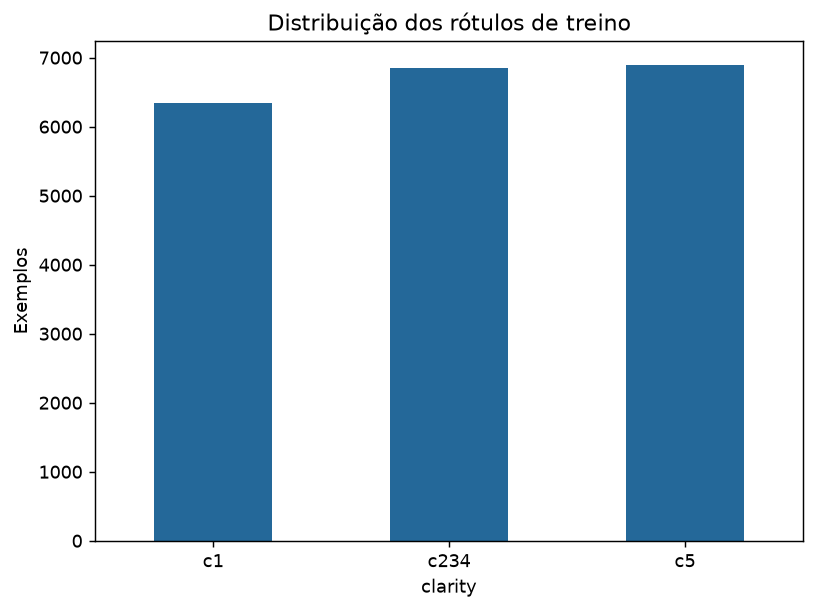

In [2]:
train = pd.read_excel(ROOT / "Dataset/train.xlsx")
valid = train.dropna(subset=["resp_text", "clarity"]).copy()
valid = valid.loc[valid.resp_text.astype(str).str.strip().ne("")]
groups = normalized_groups(valid.resp_text)
conflicts = valid.assign(grupo=groups).groupby("grupo").clarity.nunique()
display(pd.DataFrame({"Medida": ["Linhas originais", "Linhas válidas", "Grupos textuais", "Grupos com rótulos conflitantes"], "Valor": [len(train), len(valid), groups.nunique(), int((conflicts > 1).sum())]}))
counts = valid.clarity.value_counts().reindex(["c1", "c234", "c5"], fill_value=0)
display(counts.rename("Exemplos").to_frame())
counts.plot.bar(color="#246899", rot=0, title="Distribuição dos rótulos de treino")
plt.ylabel("Exemplos")
plt.tight_layout()
plt.show()


## Comparação das métricas registradas
O desvio é entre dobras quando disponível. Ausência de desvio no resumo não significa desvio zero.

In [3]:
baseline = json.loads((ROOT / "baseline_results/test1_rotulado.json").read_text(encoding="utf-8"))
classic = json.loads((ROOT / "classical_selection/summary.json").read_text(encoding="utf-8"))
bert = json.loads((ROOT / "modelo_bertimbau/summary.json").read_text(encoding="utf-8"))
rows = [{"Modelo": "Baseline TF-IDF + LR", "Acurácia CV seleção": baseline.get("selection_cv_accuracy", baseline.get("oof_accuracy")), "DP": float("nan"), "Parâmetros": json.dumps(baseline["best_params"], ensure_ascii=False)}]
rows += [{"Modelo": r["model"], "Acurácia CV seleção": r["mean_accuracy"], "DP": r["std_accuracy"], "Parâmetros": json.dumps(r["best_params"], ensure_ascii=False)} for r in classic["all_results"]]
rows.append({"Modelo": "BERTimbau Base", "Acurácia CV seleção": bert["cross_validation_accuracy"], "DP": float("nan"), "Parâmetros": json.dumps(bert["best_params"], ensure_ascii=False)})
results = pd.DataFrame(rows).sort_values("Acurácia CV seleção", ascending=False)
display(results.style.format({"Acurácia CV seleção": "{:.2%}", "DP": "{:.2%}"}, na_rep="Não registrado"))


,Modelo,Acurácia CV seleção,DP,Parâmetros
1,TF-IDF palavras + Regressão Logística,45.71%,0.97%,"{""model__C"": 0.5}"
6,BERTimbau Base,45.68%,Não registrado,"{""learning_rate"": 3e-05, ""num_train_epochs"": 3, ""weight_decay"": 0.0}"
2,TF-IDF palavras+caracteres + Regressão Logística,45.45%,0.59%,"{""model__C"": 0.5}"
0,Baseline TF-IDF + LR,45.39%,Não registrado,"{""logistic_regression__C"": 1.0, ""tfidf__max_df"": 0.95, ""tfidf__min_df"": 1, ""tfidf__ngram_range"": [1, 2]}"
3,TF-IDF palavras+caracteres + ComplementNB,45.14%,0.49%,"{""model__alpha"": 0.3}"
4,TF-IDF palavras+caracteres + LinearSVC,44.53%,0.82%,"{""model__C"": 0.3}"
5,TF-IDF palavras+caracteres + SGD modified-huber,43.76%,1.01%,"{""model__alpha"": 0.0001}"


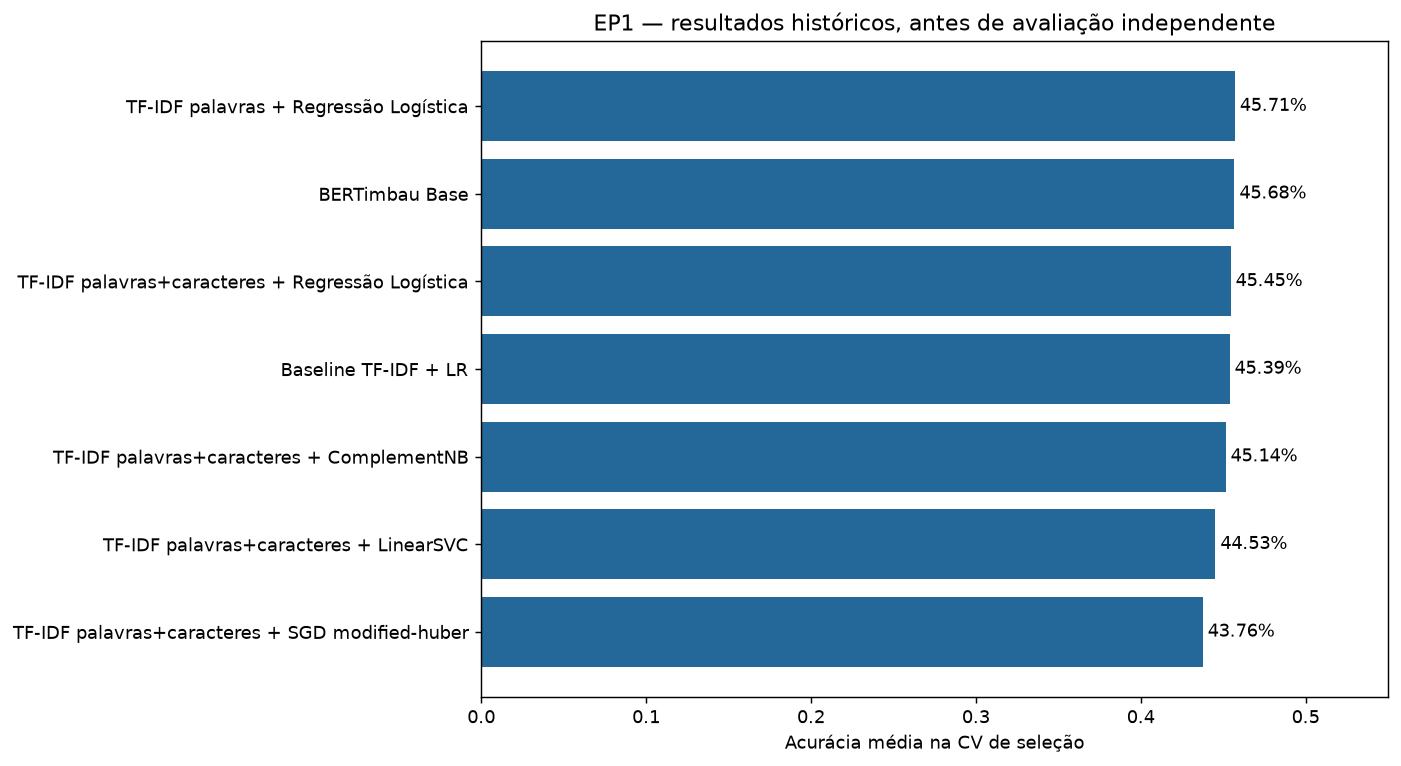

In [4]:
plot = results.sort_values("Acurácia CV seleção")
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(plot.Modelo, plot["Acurácia CV seleção"], color="#246899")
for i, value in enumerate(plot["Acurácia CV seleção"]):
    ax.text(value + 0.003, i, f"{value:.2%}", va="center")
ax.set_xlim(0, max(0.55, float(plot["Acurácia CV seleção"].max()) + 0.08))
ax.set_xlabel("Acurácia média na CV de seleção")
ax.set_title("EP1 — resultados históricos, antes de avaliação independente")
plt.tight_layout()
plt.show()


## Auditoria da entrega disponível
O arquivo de teste não rotulado permite verificar formato e alinhamento, mas não calcular acurácia, F1 ou matriz de confusão.

In [5]:
test = pd.read_excel(ROOT / "Dataset/test1.xlsx", keep_default_na=False)
prediction = pd.read_excel(ROOT / "baseline_results/test1_rotulado.xlsx", keep_default_na=False)
assert test.resp_text.tolist() == prediction.resp_text.tolist(), "Ordem ou conteúdo dos textos mudou."
assert prediction.clarity.isin(["c1", "c234", "c5"]).all()
overlap = normalized_groups(test.resp_text).isin(set(groups))
display(pd.DataFrame({"Medida": ["Exemplos do teste", "Predições válidas", "Textos do teste também presentes no treino", "Rótulos de referência disponíveis no teste"], "Valor": [len(test), len(prediction), int(overlap.sum()), int(test.clarity.astype(str).str.strip().ne("").sum())]}))
display(prediction.clarity.value_counts().rename("Predições da baseline").to_frame())


,Medida,Valor
0,Exemplos do teste,900
1,Predições válidas,900
2,Textos do teste também presentes no treino,105
3,Rótulos de referência disponíveis no teste,0


,Predições da baseline
clarity,
c5,326
c234,311
c1,263


## Conclusão e limitações

Os resumos registram aproximadamente **45,39%** para a baseline, **45,71%** para o vencedor da seleção clássica e **45,68%** para o BERTimbau Base. As diferenças pequenas não demonstram superioridade estatística.

- A CV usada para selecionar hiperparâmetros não é uma avaliação final independente; o nome histórico `oof_accuracy` não significa que vetores OOF foram armazenados.
- Sem referência rotulada do Teste 1 neste projeto, não se calcula acurácia de teste nem matriz de confusão.
- O agrupamento protege contra respostas equivalentes segundo normalização NFKC, caixa e espaços; não detecta todas as paráfrases.
- Textos repetidos com notas diferentes mostram ambiguidade do alvo. Sobreposição entre treino e teste limita conclusões de generalização.
- No BERTimbau, documentos longos geram mais janelas de treino e recebem maior peso efetivo. A inferência agrega logits por documento.
- Os dados e os artefatos históricos foram preservados pela revisão; não foi executado novo grid search.
